In [2]:
import re

import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

# Keep negations, since they flip the sentiment of a phrase
stop_words = set(stopwords.words("english")) - {"no", "nor", "not"}
lemmatizer = WordNetLemmatizer()

In [3]:
def clean_text(text):
  text = text.lower().replace("’", "'")
  # Remove HTML tags and expand negative contractions (didn't -> did not)
  text = re.sub(r"<[^>]+>", " ", text)
  text = text.replace("won't", "will not").replace("can't", "can not")
  text = re.sub(r"n't\b", " not", text)
  # Keep letters only, which also removes punctuation and digits
  text = re.sub(r"[^a-z\s]", " ", text)
  tokens = [word for word in text.split() if word not in stop_words]
  tokens = [
      lemmatizer.lemmatize(lemmatizer.lemmatize(word, pos="v"))
      for word in tokens
  ]
  return " ".join(tokens)

In [4]:
def load_dataset(file_path, text_column, target_column):
  df = pd.read_csv(file_path)
  # Keep only the two polarities (drops neutral reviews)
  df = df[df[target_column].isin(["positive", "negative"])].copy()
  df = df.dropna(subset=[text_column])
  df["clean_text"] = df[text_column].apply(clean_text)
  X = df["clean_text"]
  y = (df[target_column] == "positive").astype(int)
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42, stratify=y
  )
  return df, X_train, X_test, y_train, y_test

In [5]:
def build_pipeline(model):
  # The vectorizer lives inside the pipeline so it is fit on training text only
  return Pipeline([
      ("tfidf", TfidfVectorizer(max_features=5000)),
      ("model", model),
  ])

In [6]:
def print_scores(name, y_test, y_pred, cv_scores):
  accuracy = accuracy_score(y_test, y_pred)
  precision = precision_score(y_test, y_pred, zero_division=0)
  recall = recall_score(y_test, y_pred, zero_division=0)
  f1 = f1_score(y_test, y_pred, zero_division=0)
  print(f"\n=== {name} ===")
  print(f"CV Accuracy: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
  print(f"Test Accuracy: {accuracy:.4f}")
  print(f"Precision: {precision:.4f}")
  print(f"Recall: {recall:.4f}")
  print(f"F1: {f1:.4f}")
  print("\nClassification report:")
  print(
      classification_report(
          y_test, y_pred, target_names=["negative", "positive"],
          zero_division=0,
      )
  )
  return {
      "CV Accuracy": cv_scores.mean(),
      "Test Accuracy": accuracy,
      "Precision": precision,
      "Recall": recall,
      "F1": f1,
  }

In [7]:
def train_classifier(name, model, X_train, X_test, y_train, y_test):
  pipeline = build_pipeline(model)
  n_splits = min(5, y_train.value_counts().min())
  cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
  cv_scores = cross_val_score(
      pipeline, X_train, y_train, cv=cv, scoring="accuracy"
  )
  pipeline.fit(X_train, y_train)
  y_pred = pipeline.predict(X_test)
  scores = print_scores(name, y_test, y_pred, cv_scores)
  return y_pred, scores, pipeline

In [8]:
def plot_confusion_matrices(y_test, all_predictions):
  fig, axes = plt.subplots(1, len(all_predictions), figsize=(12, 5))

  for i, name in enumerate(all_predictions):
    cm = confusion_matrix(y_test, all_predictions[name], labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["negative", "positive"],
        yticklabels=["negative", "positive"],
        ax=axes[i],
    )
    axes[i].set_title(f"{name}: Confusion Matrix")
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

  plt.tight_layout()
  plt.show()

In [9]:
def predict_sentiment(text, models):
  cleaned = clean_text(text)
  print(f'\nText: "{text}"')
  if not cleaned:
    print("  No usable words left after cleaning")
    return
  for name in models:
    proba = models[name].predict_proba([cleaned])[0]
    label = "positive" if proba[1] >= 0.5 else "negative"
    print(f"  {name}: {label} ({max(proba):.1%} confidence)")

In [10]:
def interactive_test(models):
  print("Type a review to classify it (press Enter on an empty line to stop)")
  while True:
    text = input("Review: ")
    if not text.strip():
      break
    predict_sentiment(text, models)

In [11]:
file_path = "sentiment_reviews.csv"
text_column = "review_text"
target_column = "sentiment"

df, X_train, X_test, y_train, y_test = load_dataset(
    file_path, text_column, target_column
)
print(df[[text_column, "clean_text"]].head())
print(df[target_column].value_counts())
print(f"Train: {len(X_train)} reviews, Test: {len(X_test)} reviews")

                                         review_text  \
0  The product quality is exceptional, exceeded a...   
1  Terrible customer service and the item arrived...   
3  Absolutely love this! Easy to setup, robust, a...   
4  Stopped working after two days. Extremely disa...   
5  Customer support helped resolve my setup quest...   

                                          clean_text  
0     product quality exceptional exceed expectation  
1  terrible customer service item arrive complete...  
3  absolutely love easy setup robust work flawlessly  
4    stop work two day extremely disappoint purchase  
5  customer support help resolve setup question w...  
sentiment
positive    5
negative    4
Name: count, dtype: int64
Train: 7 reviews, Test: 2 reviews


In [12]:
nb_pred, nb_scores, nb_model = train_classifier(
    "Naive Bayes", MultinomialNB(), X_train, X_test, y_train, y_test
)
lr_pred, lr_scores, lr_model = train_classifier(
    "Logistic Regression", LogisticRegression(max_iter=1000),
    X_train, X_test, y_train, y_test,
)

vocabulary = nb_model.named_steps["tfidf"].get_feature_names_out()
print(f"\nTF-IDF features: {len(vocabulary)}")
print("\n=== Benchmark Summary ===")
print(pd.DataFrame({"Naive Bayes": nb_scores, "Logistic Regression": lr_scores}).T.round(4))


=== Naive Bayes ===
CV Accuracy: 0.3333 +/- 0.2357
Test Accuracy: 0.5000
Precision: 0.5000
Recall: 1.0000
F1: 0.6667

Classification report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2


=== Logistic Regression ===
CV Accuracy: 0.3333 +/- 0.2357
Test Accuracy: 0.5000
Precision: 0.5000
Recall: 1.0000
F1: 0.6667

Classification report:
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         1
    positive       0.50      1.00      0.67         1

    accuracy                           0.50         2
   macro avg       0.25      0.50      0.33         2
weighted avg       0.25      0.50      0.33         2


TF-IDF features: 45

=== Benchmark Summary ===
      

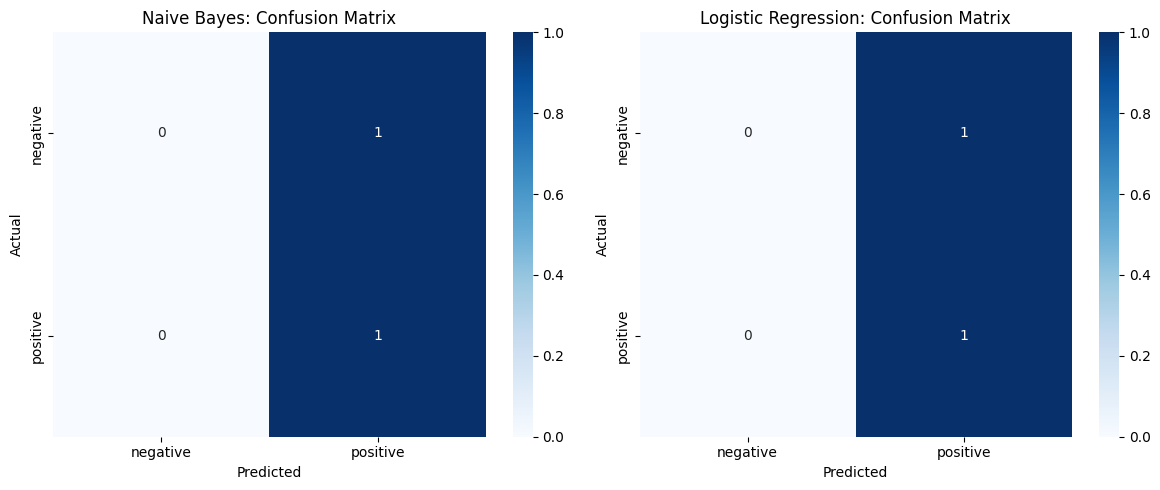

In [13]:
all_predictions = {"Naive Bayes": nb_pred, "Logistic Regression": lr_pred}
plot_confusion_matrices(y_test, all_predictions)

In [14]:
all_models = {"Naive Bayes": nb_model, "Logistic Regression": lr_model}
test_phrases = [
    "This is the best purchase I have made all year!",
    "Terrible quality, it broke after one day.",
    "It didn't work and I wouldn't recommend it.",
    "Great value and the support team was helpful.",
]
for phrase in test_phrases:
  predict_sentiment(phrase, all_models)

# Run this cell to type your own phrases (leave a line empty to stop)
# interactive_test(all_models)


Text: "This is the best purchase I have made all year!"
  Naive Bayes: positive (56.0% confidence)
  Logistic Regression: positive (56.4% confidence)

Text: "Terrible quality, it broke after one day."
  Naive Bayes: positive (51.3% confidence)
  Logistic Regression: positive (54.5% confidence)

Text: "It didn't work and I wouldn't recommend it."
  Naive Bayes: positive (55.3% confidence)
  Logistic Regression: positive (56.4% confidence)

Text: "Great value and the support team was helpful."
  Naive Bayes: positive (66.6% confidence)
  Logistic Regression: positive (62.1% confidence)
